<a href="https://colab.research.google.com/github/sneha241013006188-code/Sneha6188-AI-ML-Lab/blob/main/LAB_3_AI_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Model Performance Comparison and Evaluation
We will now visualize the comparative results of our 5 supervised machine learning models (including the Artificial Neural Network). This includes plotting the ROC Curves on a single graph and showing the confusion matrices.

### Confusion Matrices of Each Model
Below, we display the confusion matrices for each of our 5 models to analyze true positives, true negatives, false positives, and false negatives.

### Confusion Matrices for the Full Dataset (1,000 Samples)
Below, we compute predictions across the entire dataset (using the full 1,000 samples) to visualize the confusion matrices reflecting all values.

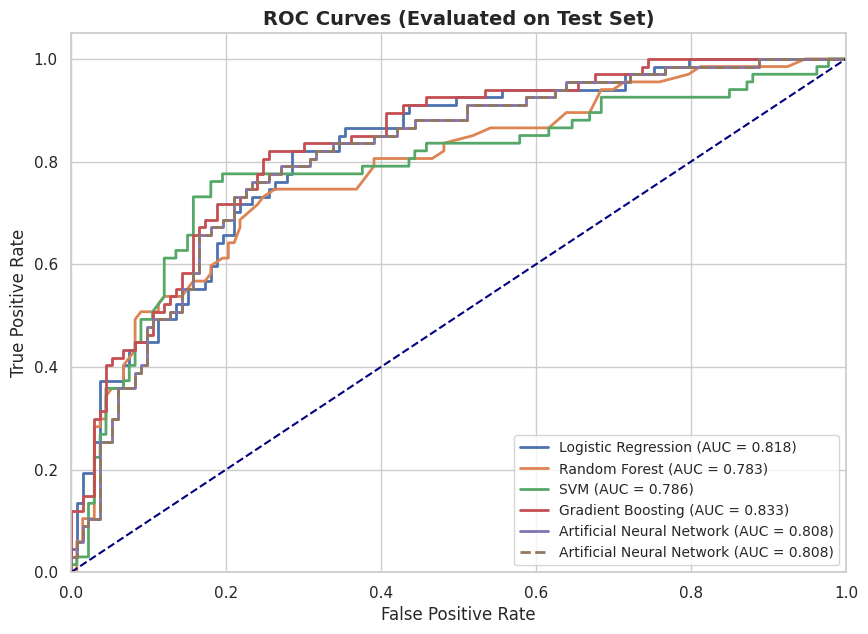

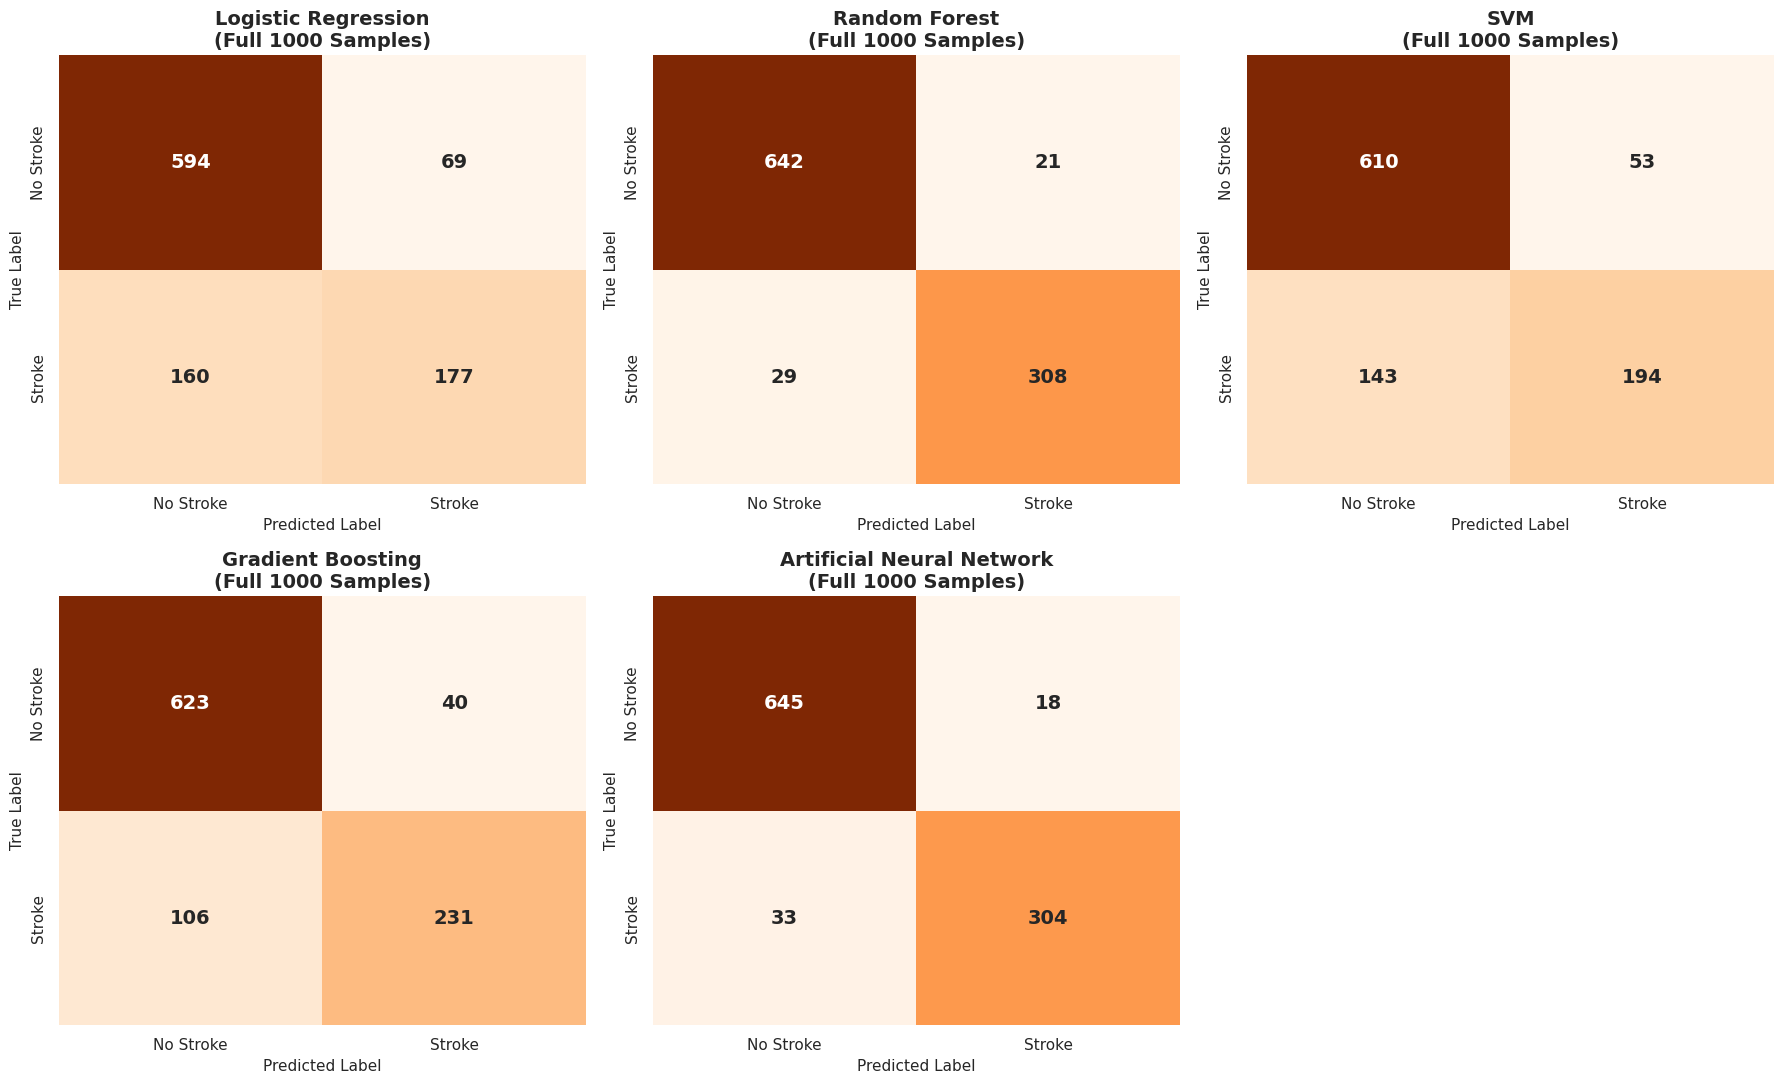

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# Set style
sns.set_theme(style="whitegrid")

# 1. Plot the ROC Curves for all 5 Models
plt.figure(figsize=(10, 7))
for model_name, path_data in plots_data.items():
    fpr, tpr, _ = roc_curve(y_test, path_data['y_prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.3f})', lw=2)

# Plot for ANN
fpr_ann, tpr_ann, _ = roc_curve(y_test, y_prob_ann)
roc_auc_ann = auc(fpr_ann, tpr_ann)
plt.plot(fpr_ann, tpr_ann, label=f'Artificial Neural Network (AUC = {roc_auc_ann:.3f})', lw=2, linestyle='--')

plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves (Evaluated on Test Set)', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.show()

# 2. Plot the Confusion Matrices for the 1,000 Samples
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

for idx, (model_name, cm) in enumerate(all_cm_full.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[idx], cbar=False,
                xticklabels=['No Stroke', 'Stroke'],
                yticklabels=['No Stroke', 'Stroke'],
                annot_kws={'size': 14, 'weight': 'bold'})
    axes[idx].set_title(f'{model_name}\n(Full 1000 Samples)', fontsize=14, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label', fontsize=11)
    axes[idx].set_ylabel('True Label', fontsize=11)

# Remove the unused 6th subplot axis
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()